In [1]:
import pandas as pd
import numpy as np
from collections import Counter
from nltk.util import bigrams
from tokenizers import Tokenizer
from tokenizers.models import BPE
from tokenizers.trainers import BpeTrainer
from tokenizers.pre_tokenizers import Metaspace
from collections import Counter
import scipy
from scipy.special import softmax
import utils
import loglin
from sklearn.metrics import accuracy_score

In [2]:
splits = {'train': 'data/train-00000-of-00001.parquet', 'test': 'data/test-00000-of-00001.parquet'}
df_train = pd.read_parquet("hf://datasets/mteb/imdb/" + splits["train"])
df_test = pd.read_parquet("hf://datasets/mteb/imdb/" + splits["test"])

In [3]:
print("Train data:")
print(df_train.head())
print("Test data:")
print(df_test.head())

Train data:
                                                text  label label_text
0  I rented I AM CURIOUS-YELLOW from my video sto...      0   negative
1  "I Am Curious: Yellow" is a risible and preten...      0   negative
2  If only to avoid making this type of film in t...      0   negative
3  This film was probably inspired by Godard's Ma...      0   negative
4  Oh, brother...after hearing about this ridicul...      0   negative
Test data:
                                                text  label label_text
0  I love sci-fi and am willing to put up with a ...      0   negative
1  Worth the entertainment value of a rental, esp...      0   negative
2  its a totally average film with a few semi-alr...      0   negative
3  STAR RATING: ***** Saturday Night **** Friday ...      0   negative
4  First off let me say, If you haven't enjoyed a...      0   negative


In [4]:
print("Train label distribution:")
print(df_train['label'].value_counts())
print("Total amount of train entries:")
print(len(df_train))
print("Test label distribution:")
print(df_test['label'].value_counts())
print("Total amount of test entries:")
print(len(df_test))

Train label distribution:
label
1    12472
0    12432
Name: count, dtype: int64
Total amount of train entries:
24904
Test label distribution:
label
1    12412
0    12266
Name: count, dtype: int64
Total amount of test entries:
24678


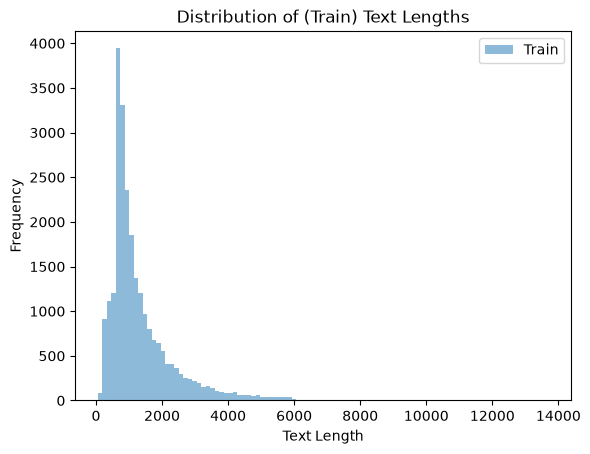

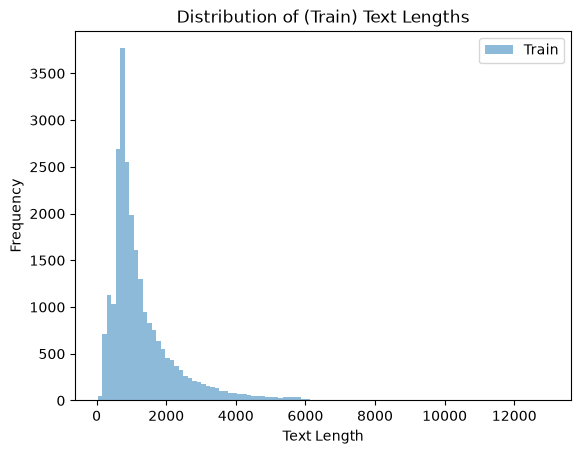

In [5]:
import matplotlib.pyplot as plt

plt.hist([len(text) for text in df_train['text']], bins=100, alpha=0.5, label='Train')
plt.xlabel('Text Length')
plt.ylabel('Frequency')
plt.title('Distribution of (Train) Text Lengths')
plt.legend()
plt.show()

plt.hist([len(text) for text in df_test['text']], bins=100, alpha=0.5, label='Train')
plt.xlabel('Text Length')
plt.ylabel('Frequency')
plt.title('Distribution of (Train) Text Lengths')
plt.legend()
plt.show()


The dataset is divided into a train set of 24904 rows and a test set of 24678 rows. Each row contains four columns: the review text, a label (0 for negative, 1 for positive), a label_text (negative or positive) and split (train or test). Both sets are almost equally balanced: the training set consists of 12472 positive (50.08%) and 12432 negative (50.02%) reviews, while the test set contains 12412 positive (50.30%) and 12266 negative (49.70%) reviews. Because the classes are evenly distributed, accuracy can be used as an evaluation metric for this analysis.

## Tokenizer

In [6]:
# I used the same parameteres as the tutorial used in the AG news example
tokenizer = Tokenizer(BPE(unk_token="[UNK]"))
tokenizer.pre_tokenizer = Metaspace()
trainer = BpeTrainer(vocab_size=1000, min_frequency=2, special_tokens=["[UNK]"])
corpus = df_train['text'].tolist()
tokenizer.train_from_iterator(corpus, trainer)

sample_text = df_test["text"].iloc[0]
output = tokenizer.encode(sample_text)
print(sample_text)
print(output.tokens)
print(output.ids)




I love sci-fi and am willing to put up with a lot. Sci-fi movies/TV are usually underfunded, under-appreciated and misunderstood. I tried to like this, I really did, but it is to good TV sci-fi as Babylon 5 is to Star Trek (the original). Silly prosthetics, cheap cardboard sets, stilted dialogues, CG that doesn't match the background, and painfully one-dimensional characters cannot be overcome with a 'sci-fi' setting. (I'm sure there are those of you out there who think Babylon 5 is good sci-fi TV. It's not. It's clichéd and uninspiring.) While US viewers might like emotion and character development, sci-fi is a genre that does not take itself seriously (cf. Star Trek). It may treat important issues, yet not as a serious philosophy. It's really difficult to care about the characters here as they are not simply foolish, just missing a spark of life. Their actions and reactions are wooden and predictable, often painful to watch. The makers of Earth KNOW it's rubbish as they have to al

# Text representation spaces

## Token indicators

In [7]:
class TokenIndicator:

    def __init__(self, tokenizer: Tokenizer):
        self.tokenizer = tokenizer
        
    def __len__(self) -> int:
        """Dimensionality of the representation space"""
        return len(self.tokenizer.get_vocab())

    def __call__(self, x: str) -> 'np.array':
        """Represent x as a D-dimensional vector of real numbers"""
        unique_token_ids = list(set(self.tokenizer.encode(x).ids))

        # A 0 vector with the same length as the vocabulary except in positions corresponding 
        # to tokens appearing in the document
        vector = np.zeros(len(self))
        vector[unique_token_ids] = 1
        return vector

In [8]:
indicator = TokenIndicator(tokenizer)
indicator_output = indicator(sample_text)

print(indicator_output.sum())
print(len(indicator_output))

261.0
1000


## Bag of Words

In [9]:
class BagOfWords:

    def __init__(self, tokenizer: Tokenizer):
        self.tokenizer = tokenizer
        
    def __len__(self) -> int:
        """Dimensionality of the representation space"""
        return len(self.tokenizer.get_vocab())

    def __call__(self, x: str) -> 'np.array':
        """Represent x as a D-dimensional vector of real numbers"""
        token_ids = self.tokenizer.encode(x).ids
        counts = Counter(token_ids)

        vector = np.zeros(len(self))
        for token_id, count in counts.items():
            vector[token_id] = float(count)
        return vector

In [10]:
bow = BagOfWords(tokenizer)
bow_output = bow(sample_text)

print(bow_output.sum())
print(len(bow_output))

513.0
1000


## Bag of Bigrams

In [11]:
class BagOfBigrams:

    def __init__(self, tokenizer: Tokenizer):
        self.tokenizer = tokenizer
        self.vocab_size = tokenizer.get_vocab_size()
        
    def __len__(self) -> int:
        """Dimensionality of the representation space"""
        return len(self.tokenizer.get_vocab())**2

    def __call__(self, x: str) -> 'np.array':
        """Represent x as a D-dimensional vector of real numbers"""
        token_ids = self.tokenizer.encode(x).ids
        bi_grams = bigrams(token_ids)

        bigram_ids = [id1*self.vocab_size + id2 for id1, id2 in bi_grams]
        counts = Counter(bigram_ids)

        vector = np.zeros(len(self))
        for bigram_id, count in counts.items():
            vector[bigram_id] = float(count)
        return vector

In [12]:
bob = BagOfBigrams(tokenizer)
bob_output = bob(sample_text)

print(bob_output.sum())
print(len(bob_output))

512.0
1000000


## Loglin

In [13]:
train_data = list(zip(df_train['text'], df_train['label']))
encoders = [TokenIndicator, BagOfWords]
for enc in encoders:
    encoder = enc(tokenizer)
    logistic_model = loglin.fit(train_data, encoder, save_to=None)
    logistic_predictions = loglin.predict(df_test['text'].tolist(), logistic_model, encoder)
    accuracy = accuracy_score(df_test['label'].tolist(), logistic_predictions)
    print(enc.__name__)
    print(accuracy)

/home/beau/Documents/msc/nlp/nlp1-student-tutorial1-2026/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/beau/Documents/msc/nlp/nlp1-student-tutorial1-2026/.venv/lib/python3.13/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


TokenIndicator
0.8200421427992544


/home/beau/Documents/msc/nlp/nlp1-student-tutorial1-2026/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/beau/Documents/msc/nlp/nlp1-student-tutorial1-2026/.venv/lib/python3.13/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


BagOfWords
0.8274981765134938


In [14]:
import smlp
from sklearn.model_selection import train_test_split
from pathlib import Path
import torch
import experiment

device = "cuda" if torch.cuda.is_available() else "cpu"

In [15]:
train_data = list(zip(df_train['text'], df_train['label']))

k = 5

cross_validation_sets = experiment.cross_validation_split(
    pairs=train_data,
    k=k,
    seed=42
)

In [19]:
results_folder = Path("./results/cross_validation")
results_folder.mkdir(parents=True, exist_ok=True)

encoders = [
    TokenIndicator(tokenizer),
    BagOfWords(tokenizer)
]

loglin_results = {}

for encoder in encoders:

    print(f"\nEncoder: {encoder.__class__.__name__}")

    results = experiment.cross_validation_experiment(
        data_splits=cross_validation_sets,
        outcome_space=[0, 1],
        encoder=encoder,
        model_option="logistic",
        save_to=str(results_folder / encoder.__class__.__name__)
    )

    loglin_results[encoder.__class__.__name__] = results

    accuracies = list(results["accuracies"].values())

    print("Fold accuracies:", accuracies)
    print(f"Mean accuracy: {np.mean(accuracies):.4f}")
    print(f"Standard deviation: {np.std(accuracies):.4f}")


Encoder: TokenIndicator


  0%|          | 0/5 [00:00<?, ?it/s]

/home/beau/Documents/msc/nlp/nlp1-student-tutorial1-2026/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/beau/Documents/msc/nlp/nlp1-student-tutorial1-2026/.venv/lib/python3.13/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/beau/Documents/msc/nlp/nlp1-student-tutorial1-2026/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/beau/Documents/msc/nlp/nlp1-student-tutorial1-2026/.venv/lib/python3.13/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_i

KeyboardInterrupt: 

## sMLP Cross-validation

In [14]:
mlp_results = {}

for encoder in encoders:

    print(f"\nEncoder: {encoder.__class__.__name__}")

    results = experiment.cross_validation_experiment(
        data_splits=cross_validation_sets,
        outcome_space=[0, 1],
        encoder=encoder,
        model_option="mlp",
        save_to=str(results_folder / f"MLP_{encoder.__class__.__name__}"),
        smlp_args={
            "hidden_dim": 128,
            "dropout": 0.1,
            "batch_size": 64,
            "learning_rate": 1e-4,
            "weight_decay": 1e-4,
            "num_epochs": 10,
            "device": device
        }
    )

    mlp_results[encoder.__class__.__name__] = results

    accuracies = list(results["accuracies"].values())

    print("Fold accuracies:", accuracies)
    print(f"Mean accuracy: {np.mean(accuracies):.4f}")
    print(f"Standard deviation: {np.std(accuracies):.4f}")

NameError: name 'encoders' is not defined

In [ ]:
summary = []

for name, results in loglin_results.items():
    accuracies = list(results["accuracies"].values())

    summary.append({
        "Model": "Logistic Regression",
        "Encoder": name,
        "Mean accuracy": np.mean(accuracies),
        "Std": np.std(accuracies)
    })

for name, results in mlp_results.items():
    accuracies = list(results["accuracies"].values())

    summary.append({
        "Model": "MLP",
        "Encoder": name,
        "Mean accuracy": np.mean(accuracies),
        "Std": np.std(accuracies)
    })

results_df = pd.DataFrame(summary)

results_df

,Model,Encoder,Mean accuracy,Std
0,Logistic Regression,TokenIndicator,0.823723,0.002768
1,Logistic Regression,BagOfWords,0.828060,0.006882
2,MLP,TokenIndicator,0.828220,0.003269
3,MLP,BagOfWords,0.833681,0.005089


## Train mlp on entire dataset and test on test set

In [16]:
# Use half of test set for validation and other galf for testing
train_data = list(zip(df_train['text'], df_train['label']))
test_data = list(zip(df_test['text'], df_test['label']))

validation_set, test_set = train_test_split(
    test_data,
    test_size=0.5,
    random_state=42,
    stratify=df_test['label']
)

In [17]:
# save models and outputs there to keep the directory tree organised
results_folder = Path("./results")
results_folder.mkdir(parents=True, exist_ok=True) 
results_folder

PosixPath('results')

In [18]:
encoders = [TokenIndicator(tokenizer), BagOfWords(tokenizer)]

for encoder in encoders:
    print(f"\nTraining with encoder: {encoder.__class__.__name__}")
    # Same parameters as the tutorial
    metrics, best_epoch, predictions = smlp.train_neural_network_model(
        training_set=train_data,
        validation_set=validation_set,
        num_classes=2,
        encoder=encoder,
        save_to=f'{results_folder}/{"smlp_"}{encoder.__class__.__name__}',
        hidden_dim=128,
        dropout=0.1,
        batch_size=64,
        learning_rate=1e-4,
        weight_decay=1e-4,
        num_epochs=10,
        device=device
    )


Training with encoder: TokenIndicator
Transforming documents...
Document transformation done! Time taken: 23.982 seconds
Dataloader done! Time taken: 0.359 seconds
Training...


  0%|          | 0/10 [00:00<?, ?it/s]

/home/beau/Documents/msc/nlp/NLP1_project/smlp.py:68: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/utils/tensor_new.cpp:249.)
  indices = torch.tensor([x.row, x.col], dtype=torch.long)
/home/beau/Documents/msc/nlp/NLP1_project/smlp.py:71: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/Context.cpp:916.)
  return torch.sparse_coo_tensor(indices, values, size=x.shape).coalesce()


Epoch 01 | train loss: 0.5908 | train acc: 0.6976 | val loss: 0.4841 | val acc: 0.7951
Epoch 02 | train loss: 0.4401 | train acc: 0.8087 | val loss: 0.4138 | val acc: 0.8198
Epoch 03 | train loss: 0.4015 | train acc: 0.8248 | val loss: 0.4045 | val acc: 0.8204
Epoch 04 | train loss: 0.3874 | train acc: 0.8333 | val loss: 0.4033 | val acc: 0.8228
Epoch 05 | train loss: 0.3779 | train acc: 0.8376 | val loss: 0.3937 | val acc: 0.8279
Epoch 06 | train loss: 0.3716 | train acc: 0.8403 | val loss: 0.4001 | val acc: 0.8232
Epoch 07 | train loss: 0.3671 | train acc: 0.8400 | val loss: 0.3971 | val acc: 0.8247
Epoch 08 | train loss: 0.3604 | train acc: 0.8459 | val loss: 0.3920 | val acc: 0.8266
Epoch 09 | train loss: 0.3552 | train acc: 0.8460 | val loss: 0.3915 | val acc: 0.8246
Epoch 10 | train loss: 0.3493 | train acc: 0.8505 | val loss: 0.3910 | val acc: 0.8245
Training done! Time taken: 101.702 seconds

Training with encoder: BagOfWords
Transforming documents...
Document transformation do

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.6084 | train acc: 0.6778 | val loss: 0.4980 | val acc: 0.7889
Epoch 02 | train loss: 0.4672 | train acc: 0.7989 | val loss: 0.4308 | val acc: 0.8245
Epoch 03 | train loss: 0.4150 | train acc: 0.8254 | val loss: 0.4124 | val acc: 0.8299
Epoch 04 | train loss: 0.3919 | train acc: 0.8360 | val loss: 0.4072 | val acc: 0.8321
Epoch 05 | train loss: 0.3773 | train acc: 0.8435 | val loss: 0.3968 | val acc: 0.8345
Epoch 06 | train loss: 0.3674 | train acc: 0.8466 | val loss: 0.3966 | val acc: 0.8338
Epoch 07 | train loss: 0.3570 | train acc: 0.8506 | val loss: 0.3955 | val acc: 0.8345
Epoch 08 | train loss: 0.3465 | train acc: 0.8563 | val loss: 0.3956 | val acc: 0.8354
Epoch 09 | train loss: 0.3374 | train acc: 0.8611 | val loss: 0.3926 | val acc: 0.8343
Epoch 10 | train loss: 0.3267 | train acc: 0.8646 | val loss: 0.3956 | val acc: 0.8348
Training done! Time taken: 97.559 seconds


In [19]:
for encoder in encoders:
    print(f"\nTesting for encoder: {encoder.__class__.__name__}")
    test_texts = [text for text, label in test_set]
    test_labels = [label for text, label in test_set]

    model = smlp.load(f'{results_folder}/{"smlp_"}{encoder.__class__.__name__}')

    test_probs = smlp.predict_probs(
        texts=test_texts,
        model=model,
        encoder=encoder
    )

    test_predictions = np.argmax(test_probs, axis=1)
    accuracy = accuracy_score(test_labels, test_predictions)
    print("SMLP test accuracy:", accuracy)


Testing for encoder: TokenIndicator
SMLP test accuracy: 0.8192722262744144

Testing for encoder: BagOfWords
SMLP test accuracy: 0.826241996920334


## MLP


In [20]:
import mlp

encoders = [TokenIndicator(tokenizer), BagOfWords(tokenizer)]

for encoder in encoders:
    print(f"\nTraining with encoder: {encoder.__class__.__name__}")
    # Same parameters as the tutorial
    metrics, best_epoch, predictions = mlp.train_neural_network_model(
        training_set=train_data,
        validation_set=validation_set,
        num_classes=2,
        encoder=encoder,
        save_to=f'{results_folder}/{"mlp_"}{encoder.__class__.__name__}',
        hidden_dim1=128,
        hidden_dim2=64,
        dropout=0.1,
        batch_size=64,
        learning_rate=1e-4,
        weight_decay=1e-4,
        num_epochs=10,
        device=device
    )


Training with encoder: TokenIndicator
Transforming documents...
Document transformation done! Time taken: 24.968 seconds
Dataloader done! Time taken: 0.361 seconds
Training...


  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.5781 | train acc: 0.6981 | val loss: 0.4576 | val acc: 0.7966
Epoch 02 | train loss: 0.4399 | train acc: 0.8026 | val loss: 0.4096 | val acc: 0.8186
Epoch 03 | train loss: 0.4044 | train acc: 0.8228 | val loss: 0.3966 | val acc: 0.8244
Epoch 04 | train loss: 0.3856 | train acc: 0.8312 | val loss: 0.3923 | val acc: 0.8253
Epoch 05 | train loss: 0.3743 | train acc: 0.8368 | val loss: 0.3904 | val acc: 0.8240
Epoch 06 | train loss: 0.3625 | train acc: 0.8420 | val loss: 0.3985 | val acc: 0.8230
Epoch 07 | train loss: 0.3547 | train acc: 0.8476 | val loss: 0.3904 | val acc: 0.8218
Epoch 08 | train loss: 0.3439 | train acc: 0.8513 | val loss: 0.3965 | val acc: 0.8236
Epoch 09 | train loss: 0.3337 | train acc: 0.8580 | val loss: 0.3926 | val acc: 0.8211
Epoch 10 | train loss: 0.3238 | train acc: 0.8601 | val loss: 0.4020 | val acc: 0.8235
Training done! Time taken: 96.729 seconds

Training with encoder: BagOfWords
Transforming documents...
Document transformation don

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.6338 | train acc: 0.6487 | val loss: 0.5194 | val acc: 0.7725
Epoch 02 | train loss: 0.4845 | train acc: 0.7857 | val loss: 0.4404 | val acc: 0.8166
Epoch 03 | train loss: 0.4320 | train acc: 0.8145 | val loss: 0.4175 | val acc: 0.8249
Epoch 04 | train loss: 0.4023 | train acc: 0.8299 | val loss: 0.4050 | val acc: 0.8288
Epoch 05 | train loss: 0.3840 | train acc: 0.8354 | val loss: 0.3987 | val acc: 0.8286
Epoch 06 | train loss: 0.3658 | train acc: 0.8457 | val loss: 0.3969 | val acc: 0.8314
Epoch 07 | train loss: 0.3535 | train acc: 0.8498 | val loss: 0.3970 | val acc: 0.8290
Epoch 08 | train loss: 0.3394 | train acc: 0.8570 | val loss: 0.3947 | val acc: 0.8312
Epoch 09 | train loss: 0.3252 | train acc: 0.8628 | val loss: 0.3974 | val acc: 0.8286
Epoch 10 | train loss: 0.3113 | train acc: 0.8705 | val loss: 0.3986 | val acc: 0.8294
Training done! Time taken: 111.337 seconds


In [21]:
for encoder in encoders:
    print(f"\nTesting for encoder: {encoder.__class__.__name__}")
    test_texts = [text for text, label in test_set]
    test_labels = [label for text, label in test_set]

    model = mlp.load(f'{results_folder}/{"mlp_"}{encoder.__class__.__name__}')

    test_probs = mlp.predict_probs(
        texts=test_texts,
        model=model,
        encoder=encoder
    )

    test_predictions = np.argmax(test_probs, axis=1)
    accuracy = accuracy_score(test_labels, test_predictions)
    print("MLP test accuracy:", accuracy)


Testing for encoder: TokenIndicator
MLP test accuracy: 0.8160304724856147

Testing for encoder: BagOfWords
MLP test accuracy: 0.8284301807277737
